In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, random, warnings
warnings.filterwarnings('ignore')

# Install required packages
# (these get wiped every session — always reinstall)
os.system('pip install -q timm scikit-learn matplotlib seaborn')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as transforms
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    confusion_matrix, classification_report
)

# ── Paths ──────────────────────────────────────────────────
PROJECT_DIR  = '/content/drive/MyDrive/glaucoma-mtl'
DATA_DIR     = f'{PROJECT_DIR}/data/smdg19'
RESULTS_DIR  = f'{PROJECT_DIR}/results/baseline_mobilenetv3_large'
CKPT_DIR     = f'{PROJECT_DIR}/checkpoints'
CSV_PATH     = f'{DATA_DIR}/metadata - standardized.csv'
CLEAN_CSV    = f'{PROJECT_DIR}/metadata_clean.csv'

for d in [RESULTS_DIR, CKPT_DIR]:
    os.makedirs(d, exist_ok=True)

# ── Reproducibility ────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")
print("Setup complete.")



Mounted at /content/drive
Device: cuda
GPU: Tesla T4
Setup complete.


In [ ]:
import os

data_dir = '/content/drive/MyDrive/glaucoma-mtl/data/smdg19'
print("Data dir exists:", os.path.exists(data_dir))
print("\nContents:")
if os.path.exists(data_dir):
    for f in os.listdir(data_dir):
        size = os.path.getsize(os.path.join(data_dir, f)) if os.path.isfile(os.path.join(data_dir, f)) else 'DIR'
        print(f"  '{f}'  →  {size}")
else:
    print("  FOLDER DOES NOT EXIST")

Data dir exists: True

Contents:
  'metadata - standardized.csv'  →  1748428
  'vessel-artery'  →  DIR
  'full-fundus'  →  DIR
  'optic-cup'  →  DIR
  'blood-vessel'  →  DIR
  'spectral-oct'  →  DIR
  'spectral-oct-disc'  →  DIR
  'optic-disc'  →  DIR
  'spectral-oct-cup'  →  DIR
  'vessel-vein'  →  DIR


In [ ]:
import zipfile, os

DATA_DIR = '/content/drive/MyDrive/glaucoma-mtl/data/smdg19'
zip_path = f'{DATA_DIR}/multichannel-glaucoma-benchmark-dataset.zip'

print(f"Zip size: {os.path.getsize(zip_path)/(1024**3):.2f} GB")
print("Extracting remaining files (skips already-extracted ones)...")

with zipfile.ZipFile(zip_path, 'r') as z:
    all_files = z.namelist()
    print(f"Total files in zip: {len(all_files)}")

    # Only extract files that don't already exist — won't re-extract full-fundus
    missing = [f for f in all_files
               if not os.path.exists(os.path.join(DATA_DIR, f))]
    print(f"Files still to extract: {len(missing)}")

    for f in missing:
        z.extract(f, DATA_DIR)

print("\nDone. Contents now:")
for item in os.listdir(DATA_DIR):
    full = os.path.join(DATA_DIR, item)
    if os.path.isdir(full):
        count = len(os.listdir(full))
        print(f"  📁 {item}/  ({count} items)")
    else:
        size_mb = os.path.getsize(full)/(1024*1024)
        print(f"  📄 {item}  ({size_mb:.1f} MB)")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/glaucoma-mtl/data/smdg19/multichannel-glaucoma-benchmark-dataset.zip'

In [ ]:
import os

DATA_DIR = '/content/drive/MyDrive/glaucoma-mtl/data/smdg19'

# Check what's inside each folder
for folder in ['full-fundus', 'optic-disc', 'optic-cup']:
    folder_path = os.path.join(DATA_DIR, folder)
    contents = os.listdir(folder_path)
    print(f"\n{folder}/ contains {len(contents)} items:")
    for item in contents[:5]:  # show first 5
        full = os.path.join(folder_path, item)
        if os.path.isdir(full):
            subcontents = os.listdir(full)
            print(f"  📁 {item}/  ({len(subcontents)} items)")
            # Show a few files inside
            for f in subcontents[:3]:
                print(f"    - {f}")
        else:
            print(f"  📄 {item}")

# Also check what a CSV path actually looks like
import pandas as pd
df = pd.read_csv(f'{DATA_DIR}/metadata - standardized.csv')
print(f"\nSample fundus paths from CSV:")
print(df['fundus'].head(5).tolist())


full-fundus/ contains 1 items:
  📁 full-fundus/  (12466 items)
    - REFUGE1-train-348.png
    - REFUGE1-train-333.png
    - REFUGE1-train-331.png

optic-disc/ contains 1 items:
  📁 optic-disc/  (3103 items)
    - PAPILA-257.png
    - G1020-926.png
    - G1020-292.png

optic-cup/ contains 1 items:
  📁 optic-cup/  (2874 items)
    - REFUGE1-val-35.png
    - PAPILA-72.png
    - PAPILA-108.png

Sample fundus paths from CSV:
['/full-fundus/OIA-ODIR-TEST-OFFLINE-1.png', '/full-fundus/OIA-ODIR-TEST-OFFLINE-2.png', '/full-fundus/OIA-ODIR-TEST-OFFLINE-4.png', '/full-fundus/OIA-ODIR-TEST-OFFLINE-5.png', '/full-fundus/OIA-ODIR-TEST-OFFLINE-6.png']


In [ ]:
import os

print(os.listdir(DATA_DIR))
print(os.listdir(os.path.join(DATA_DIR, "full-fundus")))

['metadata - standardized.csv', 'vessel-artery', 'full-fundus', 'optic-cup', 'blood-vessel', 'spectral-oct', 'spectral-oct-disc', 'optic-disc', 'spectral-oct-cup', 'vessel-vein']
['full-fundus']


In [ ]:
import os

path1 = os.path.join(DATA_DIR, "full-fundus", "OIA-ODIR-TEST-OFFLINE-1.png")
path2 = os.path.join(DATA_DIR, "full-fundus", "full-fundus", "OIA-ODIR-TEST-OFFLINE-1.png")

print(path1, os.path.isfile(path1))
print(path2, os.path.isfile(path2))

/content/drive/MyDrive/glaucoma-mtl/data/smdg19/full-fundus/OIA-ODIR-TEST-OFFLINE-1.png False
/content/drive/MyDrive/glaucoma-mtl/data/smdg19/full-fundus/full-fundus/OIA-ODIR-TEST-OFFLINE-1.png True


Loaded CSV: 12449 rows, 48 columns

Example fundus path:
/content/drive/MyDrive/glaucoma-mtl/data/smdg19/full-fundus/full-fundus/OIA-ODIR-TEST-OFFLINE-1.png
Exists: True

Class distribution after folding suspects into glaucoma:
label
0    7549
1    4900
Name: count, dtype: int64
  0 = Non-Glaucoma: 7549
  1 = Glaucoma:     4900

Pre-computed CDR availability:
  vcdr non-null:    650
  cdr_avg non-null: 101

vcdr statistics:
count    650.000000
mean       0.576308
std        0.116395
min        0.161000
25%        0.496675
50%        0.567650
75%        0.648475
max        0.962900
Name: vcdr, dtype: float64

Spot check (20 random images): 20/20 found on disk

Checking all fundus images...
Images found:   12449
Images missing: 0

Clean dataset: 12449 usable images
Saved clean metadata to:
/content/drive/MyDrive/glaucoma-mtl/metadata_clean.csv


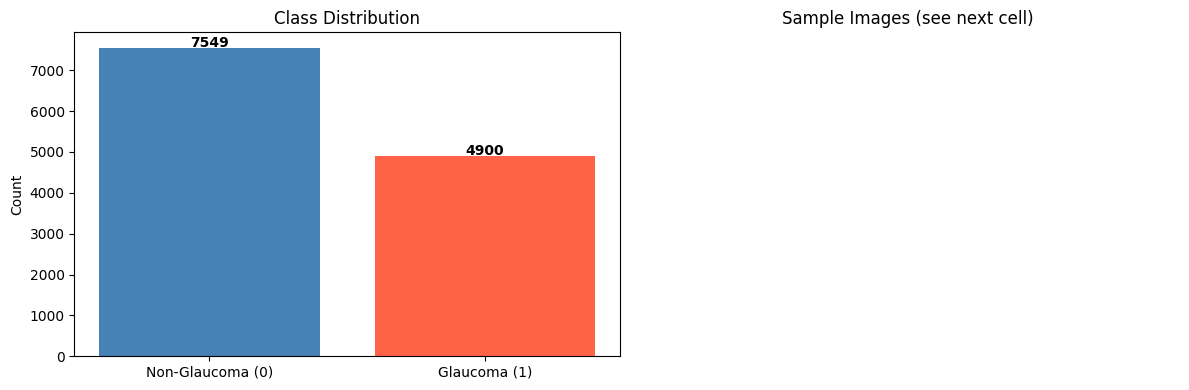

Class distribution plot saved to:
/content/drive/MyDrive/glaucoma-mtl/results/baseline_mobilenetv3_large/class_distribution.png


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Load metadata
df = pd.read_csv(CSV_PATH)
print(f"Loaded CSV: {len(df)} rows, {len(df.columns)} columns")

# ============================================================
# Step 1: Fix file paths
# ============================================================

def fix_path(rel_path):
    """
    Convert CSV relative paths to actual file locations.
    Supports both:
      DATA_DIR/full-fundus/image.png
      DATA_DIR/full-fundus/full-fundus/image.png
    """

    if pd.isna(rel_path) or str(rel_path).strip() == "":
        return None

    rel_path = str(rel_path).lstrip("/")

    # Option 1: Normal extraction
    path1 = os.path.join(DATA_DIR, rel_path)
    if os.path.isfile(path1):
        return path1

    # Option 2: Nested extraction
    parts = rel_path.split("/", 1)
    if len(parts) == 2:
        folder, filename = parts
        path2 = os.path.join(DATA_DIR, folder, folder, filename)
        if os.path.isfile(path2):
            return path2

    # Return nested path anyway (for debugging if missing)
    if len(parts) == 2:
        return path2

    return path1


# Create corrected paths
df['fundus_path'] = df['fundus'].apply(fix_path)
df['od_path'] = df['fundus_od_seg'].apply(fix_path)
df['oc_path'] = df['fundus_oc_seg'].apply(fix_path)

# Verify one example
print("\nExample fundus path:")
print(df.loc[0, 'fundus_path'])
print("Exists:", os.path.isfile(df.loc[0, 'fundus_path']))


# ============================================================
# Step 2: Fix labels
# ============================================================

# Fold glaucoma suspects (-1) into glaucoma (1)
df['label'] = df['types'].apply(lambda x: 1 if x in [1, -1] else 0)

print("\nClass distribution after folding suspects into glaucoma:")
print(df['label'].value_counts())

print(f"  0 = Non-Glaucoma: {(df['label']==0).sum()}")
print(f"  1 = Glaucoma:     {(df['label']==1).sum()}")


# ============================================================
# Step 3: Check CDR columns
# ============================================================

print("\nPre-computed CDR availability:")
print(f"  vcdr non-null:    {df['vcdr'].notna().sum()}")
print(f"  cdr_avg non-null: {df['cdr_avg'].notna().sum()}")

if df['vcdr'].notna().sum() > 0:
    print("\nvcdr statistics:")
    print(df['vcdr'].describe())


# ============================================================
# Step 4: Spot check image files
# ============================================================

sample = df.sample(20, random_state=SEED)

missing = sum(
    not os.path.isfile(path)
    for path in sample['fundus_path']
)

print(f"\nSpot check (20 random images): {20-missing}/20 found on disk")

if missing > 0:
    print("WARNING: Some sample images are missing.")


# ============================================================
# Step 5: Verify every image
# ============================================================

print("\nChecking all fundus images...")

df['fundus_exists'] = df['fundus_path'].apply(
    lambda x: os.path.isfile(x) if x else False
)

print(f"Images found:   {df['fundus_exists'].sum()}")
print(f"Images missing: {(~df['fundus_exists']).sum()}")

df_clean = df[df['fundus_exists']].copy().reset_index(drop=True)

print(f"\nClean dataset: {len(df_clean)} usable images")


# ============================================================
# Step 6: Save cleaned metadata
# ============================================================

df_clean.to_csv(CLEAN_CSV, index=False)

print(f"Saved clean metadata to:\n{CLEAN_CSV}")


# ============================================================
# Step 7: Plot class distribution
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = df_clean['label'].value_counts()

axes[0].bar(
    ['Non-Glaucoma (0)', 'Glaucoma (1)'],
    [counts.get(0, 0), counts.get(1, 0)],
    color=['steelblue', 'tomato']
)

axes[0].set_title("Class Distribution")
axes[0].set_ylabel("Count")

for i, v in enumerate([counts.get(0,0), counts.get(1,0)]):
    axes[0].text(i, v + 20, str(v), ha='center', fontweight='bold')

axes[1].axis("off")
axes[1].set_title("Sample Images (see next cell)")

plt.tight_layout()

plot_path = os.path.join(RESULTS_DIR, "class_distribution.png")
plt.savefig(plot_path, dpi=150)

plt.show()

print(f"Class distribution plot saved to:\n{plot_path}")

## Resources

### CDR DERIVATION + SUBSAMPLING

Run this ONCE before your baseline training script.

**Produces:** `metadata_final.csv` (3000 classification + CDR labels)

**What this does:**
1. Loads metadata CSV.
2. Derives VCDR from OD+OC masks for all 3102 mask-available images (for the 650 with pre-computed vcdr, uses that directly as ground truth check).
3. Subsamples 3000 images for classification (balanced 1500/1500).
4. From those 3000, marks which also have CDR labels (severity head).
5. Saves `metadata_final.csv` → replaces `metadata_clean.csv` in your pipeline.


In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

# ── Paths ─────────────────────────────────────────────────
# PROJECT_DIR, DATA_DIR, CSV_PATH are already defined in WlgqYcw78qQX
FINAL_CSV   = f'{PROJECT_DIR}/metadata_final.csv'
SEED        = 42

# ── Step 1: Load CSV and fix paths ────────────────────────
print("Loading metadata...")
df = pd.read_csv(CSV_PATH)
print(f"Total rows: {len(df)}")

df['fundus_path'] = df['fundus'].apply(fix_path)
df['od_path']     = df['fundus_od_seg'].apply(fix_path)
df['oc_path']     = df['fundus_oc_seg'].apply(fix_path)

# Fix label: fold suspects (-1) into glaucoma (1)
df['label'] = df['types'].apply(lambda x: 1 if x in [1, -1] else 0)


Loading metadata...
Total rows: 12449


In [ ]:
# ── Step 2: Derive VCDR from OD+OC masks ─────────────────
# VCDR = vertical height of OC / vertical height of OD
# We read each mask, binarize it, find the vertical extent (row span)
# of the white region, and divide OC height by OD height.
# Returns None for missing/corrupt/empty masks.

def derive_vcdr(od_path, oc_path):
    """
    Derive Vertical Cup-to-Disc Ratio from binary segmentation masks.
    Returns float (0-1) or None if masks are invalid.
    """
    try:
        if od_path is None or oc_path is None:
            return None
        if not os.path.isfile(od_path) or not os.path.isfile(oc_path):
            return None

        od_img = np.array(Image.open(od_path).convert('L'))
        oc_img = np.array(Image.open(oc_path).convert('L'))

        # Binarize: threshold at 128
        od_mask = od_img > 128
        oc_mask = oc_img > 128

        # Find vertical extent (rows that contain white pixels)
        od_rows = np.any(od_mask, axis=1)
        oc_rows = np.any(oc_mask, axis=1)

        od_height = od_rows.sum()
        oc_height = oc_rows.sum()

        if od_height == 0:
            return None  # empty OD mask — invalid

        vcdr = oc_height / od_height

        # Clamp: OC should never exceed OD
        if vcdr > 1.5:
            return None  # physically impossible — corrupt mask

        return round(float(vcdr), 4)

    except Exception:
        return None


# Only derive for rows that have both masks
has_od  = df['od_path'].notna()
has_oc  = df['oc_path'].notna()
has_both = has_od & has_oc

print(f"\nImages with both OD+OC masks: {has_both.sum()}")
print("Deriving VCDR from masks (takes ~2-3 minutes)...")

df['vcdr_derived'] = None
mask_rows = df[has_both].index

for idx in tqdm(mask_rows):
    row = df.loc[idx]
    derived = derive_vcdr(row['od_path'], row['oc_path'])
    df.at[idx, 'vcdr_derived'] = derived

# For rows with pre-computed vcdr, use that as the primary label
# (more reliable — from ophthalmologist annotation, not mask derivation)
# For mask-only rows, use derived value
df['vcdr_final'] = df['vcdr']  # start with pre-computed
# Fill in derived values where pre-computed is missing
missing_vcdr = df['vcdr_final'].isna() & df['vcdr_derived'].notna()
df.loc[missing_vcdr, 'vcdr_final'] = df.loc[missing_vcdr, 'vcdr_derived']

# Stage severity
def stage(v):
    if pd.isna(v):
        return None
    v = float(v)
    if v < 0.65:
        return 'mild'
    elif v <= 0.85:
        return 'moderate'
    else:
        return 'severe'

df['severity_stage'] = df['vcdr_final'].apply(stage)
df['has_severity']   = df['vcdr_final'].notna().astype(int)

print(f"\n=== CDR AVAILABILITY AFTER DERIVATION ===")
print(f"Pre-computed vcdr:    {df['vcdr'].notna().sum()}")
print(f"Derived vcdr:         {df['vcdr_derived'].notna().sum()}")
print(f"Total with vcdr_final:{df['vcdr_final'].notna().sum()}")
print(f"\nSeverity distribution:")
print(df['severity_stage'].value_counts())

# Verify images exist on disk
print("\nVerifying fundus images exist on disk...")
df['fundus_exists'] = df['fundus_path'].apply(
    lambda p: os.path.isfile(p) if p else False
)
df_valid = df[df['fundus_exists']].copy().reset_index(drop=True)
print(f"Valid images (exist on disk): {len(df_valid)}")



Images with both OD+OC masks: 3102
Deriving VCDR from masks (takes ~2-3 minutes)...


100%|██████████| 3102/3102 [17:58<00:00,  2.88it/s]



=== CDR AVAILABILITY AFTER DERIVATION ===
Pre-computed vcdr:    650
Derived vcdr:         2873
Total with vcdr_final:2873

Severity distribution:
severity_stage
mild        2535
moderate     313
severe        25
Name: count, dtype: int64

Verifying fundus images exist on disk...
Valid images (exist on disk): 12449


In [ ]:
# ── Step 3: Subsample 3000 for classification ─────────────
# Strategy: balanced — 1500 glaucoma + 1500 non-glaucoma
# This avoids class imbalance issues and keeps training fast
# while still being large enough for a meaningful model.

print("\n=== SUBSAMPLING 3000 FOR CLASSIFICATION ===")

glaucoma_df     = df_valid[df_valid['label'] == 1]
non_glaucoma_df = df_valid[df_valid['label'] == 0]

print(f"Available glaucoma images:     {len(glaucoma_df)}")
print(f"Available non-glaucoma images: {len(non_glaucoma_df)}")

# Sample 1500 from each class (or all if fewer than 1500)
n_per_class = 1500

glaucoma_sample     = glaucoma_df.sample(
    n=min(n_per_class, len(glaucoma_df)), random_state=SEED
)
non_glaucoma_sample = non_glaucoma_df.sample(
    n=min(n_per_class, len(non_glaucoma_df)), random_state=SEED
)

df_3000 = pd.concat([glaucoma_sample, non_glaucoma_sample]).sample(
    frac=1, random_state=SEED  # shuffle
).reset_index(drop=True)

print(f"\nFinal classification subset: {len(df_3000)} images")
print(f"  Glaucoma:     {(df_3000['label']==1).sum()}")
print(f"  Non-Glaucoma: {(df_3000['label']==0).sum()}")

# ── Step 4: CDR availability within the 3000 ─────────────
print("\n=== CDR AVAILABILITY WITHIN THE 3000 ===")
has_sev = df_3000['has_severity'] == 1
print(f"Images with CDR (severity head): {has_sev.sum()}")
print(f"Images without CDR (classification only): {(~has_sev).sum()}")

# Severity distribution within those that have CDR
sev_subset = df_3000[has_sev]
print(f"\nSeverity stages in the 3000:")
print(df_3000['severity_stage'].value_counts())



=== SUBSAMPLING 3000 FOR CLASSIFICATION ===
Available glaucoma images:     4900
Available non-glaucoma images: 7549

Final classification subset: 3000 images
  Glaucoma:     1500
  Non-Glaucoma: 1500

=== CDR AVAILABILITY WITHIN THE 3000 ===
Images with CDR (severity head): 631
Images without CDR (classification only): 2369

Severity stages in the 3000:
severity_stage
mild        546
moderate     79
severe        6
Name: count, dtype: int64


In [ ]:
# ── Step 5: Save final CSV ────────────────────────────────
# Keep only columns needed by the DataLoader
keep_cols = [
    'names', 'label', 'fundus_path', 'od_path', 'oc_path',
    'vcdr_final', 'severity_stage', 'has_severity', 'types'
]
df_final = df_3000[keep_cols].copy()
df_final.to_csv(FINAL_CSV, index=False)

print(f"\n=== SAVED ===")
print(f"metadata_final.csv → {FINAL_CSV}")
print(f"Total rows: {len(df_final)}")
print(f"\nSample rows:")
print(df_final[['names','label','vcdr_final','severity_stage','has_severity']].head(10).to_string())



=== SAVED ===
metadata_final.csv → /content/drive/MyDrive/glaucoma-mtl/metadata_final.csv
Total rows: 3000

Sample rows:
                   names  label vcdr_final severity_stage  has_severity
0              G1020-538      0     0.3133           mild             1
1  EyePACS-Glaucoma-2123      1        NaN           None             0
2     OIA-ODIR-TRAIN-161      0        NaN           None             0
3              G1020-944      1        0.7       moderate             1
4              ORIGA-350      0     0.5688           mild             1
5       sjchoi86-HRF-382      1        NaN           None             0
6    EyePACS-Glaucoma-53      1        NaN           None             0
7              G1020-369      0     0.4559           mild             1
8                 BEH-40      1        NaN           None             0
9    OIA-ODIR-TRAIN-2200      0        NaN           None             0


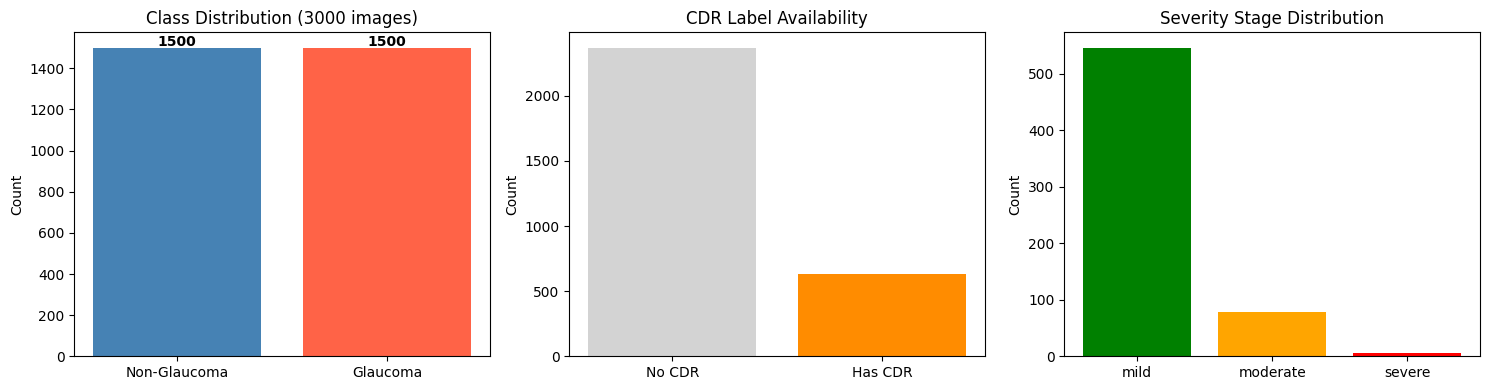

Distribution plot saved.

DONE. Now update your DataLoader to use:
  CLEAN_CSV = '/content/drive/MyDrive/glaucoma-mtl/metadata_final.csv'
The rest of your baseline script runs unchanged.


In [ ]:
# ── Step 6: Validation plots ──────────────────────────────
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Class balance
axes[0].bar(['Non-Glaucoma', 'Glaucoma'],
            [(df_final['label']==0).sum(), (df_final['label']==1).sum()],
            color=['steelblue', 'tomato'])
axes[0].set_title('Class Distribution (3000 images)')
axes[0].set_ylabel('Count')
for i, v in enumerate([(df_final['label']==0).sum(), (df_final['label']==1).sum()]):
    axes[0].text(i, v+10, str(v), ha='center', fontweight='bold')

# Severity availability
axes[1].bar(['No CDR', 'Has CDR'],
            [(~has_sev).sum(), has_sev.sum()],
            color=['lightgray', 'darkorange'])
axes[1].set_title('CDR Label Availability')
axes[1].set_ylabel('Count')

# Severity stages
stage_counts = df_final['severity_stage'].value_counts()
axes[2].bar(stage_counts.index, stage_counts.values,
            color=['green', 'orange', 'red'])
axes[2].set_title('Severity Stage Distribution')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/results/baseline_densenet121/data_distribution.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Distribution plot saved.")

print("\n" + "="*60)
print("DONE. Now update your DataLoader to use:")
print(f"  CLEAN_CSV = '{FINAL_CSV}'")
print("The rest of your baseline script runs unchanged.")
print("="*60)


In [ ]:
import pandas as pd
DATA_DIR = '/content/drive/MyDrive/glaucoma-mtl/data/smdg19'
df = pd.read_csv(DATA_DIR + '/metadata - standardized.csv')
print(df['vcdr'].notna().sum())
print(df['cdr_avg'].notna().sum())
print(df[df['vcdr'].notna()][['names','types','vcdr']].head(10))

650
101
         names  types    vcdr
4546   ORIGA-1      0  0.7097
4547   ORIGA-2      0  0.6953
4548   ORIGA-3      0  0.9629
4549   ORIGA-4      0  0.7246
4550   ORIGA-5      0  0.6138
4551   ORIGA-6      0  0.6451
4552   ORIGA-7      0  0.5255
4553   ORIGA-8      0  0.4974
4554   ORIGA-9      0  0.5273
4555  ORIGA-10      0  0.4451


In [ ]:
# Run this to see the severity distribution
import pandas as pd
DATA_DIR = '/content/drive/MyDrive/glaucoma-mtl/data/smdg19'
df = pd.read_csv(DATA_DIR + '/metadata - standardized.csv')
vcdr_df = df[df['vcdr'].notna()].copy()
vcdr_df['severity'] = vcdr_df['vcdr'].apply(
    lambda x: 'mild' if x < 0.65 else ('moderate' if x <= 0.85 else 'severe')
    )
print(vcdr_df['severity'].value_counts())
print(vcdr_df['vcdr'].describe())

severity
mild        492
moderate    147
severe       11
Name: count, dtype: int64
count    650.000000
mean       0.576308
std        0.116395
min        0.161000
25%        0.496675
50%        0.567650
75%        0.648475
max        0.962900
Name: vcdr, dtype: float64


In [ ]:
import pandas as pd

DATA_DIR = '/content/drive/MyDrive/glaucoma-mtl/data/smdg19'
df = pd.read_csv(DATA_DIR + '/metadata - standardized.csv')

# Severity from vcdr column
vcdr_df = df[df['vcdr'].notna()].copy()
vcdr_df['severity'] = vcdr_df['vcdr'].apply(
    lambda x: 'Mild (CDR < 0.65)' if x < 0.65
    else ('Moderate (0.65-0.85)' if x <= 0.85 else 'Severe (CDR > 0.85)')
)

print("=== PRE-COMPUTED vcdr (direct severity labels) ===")
print(f"Total images with vcdr: {len(vcdr_df)}")
print(vcdr_df['severity'].value_counts())

# CDR derivable from OD+OC masks
has_od = df['fundus_od_seg'].notna()
has_oc = df['fundus_oc_seg'].notna()
has_both = has_od & has_oc

print(f"\n=== DERIVABLE CDR (from OD+OC segmentation masks) ===")
print(f"Images with OD mask:       {has_od.sum()}")
print(f"Images with OC mask:       {has_oc.sum()}")
print(f"Images with BOTH (derivable CDR): {has_both.sum()}")

# Overlap
has_vcdr = df['vcdr'].notna()
overlap = has_vcdr & has_both
print(f"\n=== OVERLAP ===")
print(f"Images with BOTH vcdr AND masks: {overlap.sum()}")
print(f"Images with vcdr ONLY (no masks): {(has_vcdr & ~has_both).sum()}")
print(f"Images with masks ONLY (no vcdr): {(has_both & ~has_vcdr).sum()}")
print(f"Total usable for severity (vcdr OR masks): {(has_vcdr | has_both).sum()}")

=== PRE-COMPUTED vcdr (direct severity labels) ===
Total images with vcdr: 650
severity
Mild (CDR < 0.65)       492
Moderate (0.65-0.85)    147
Severe (CDR > 0.85)      11
Name: count, dtype: int64

=== DERIVABLE CDR (from OD+OC segmentation masks) ===
Images with OD mask:       3103
Images with OC mask:       3103
Images with BOTH (derivable CDR): 3102

=== OVERLAP ===
Images with BOTH vcdr AND masks: 650
Images with vcdr ONLY (no masks): 0
Images with masks ONLY (no vcdr): 2452
Total usable for severity (vcdr OR masks): 3102


In [ ]:
import pandas as pd
import os

DATA_DIR = '/content/drive/MyDrive/glaucoma-mtl/data/smdg19'
df = pd.read_csv(DATA_DIR + '/metadata - standardized.csv')

vcdr_df = df[df['vcdr'].notna()].copy()

def fix_path(rel_path):
    """
    Convert CSV relative paths to actual file locations.
    Supports both:
      DATA_DIR/full-fundus/image.png
      DATA_DIR/full-fundus/full-fundus/image.png
    """

    if pd.isna(rel_path) or str(rel_path).strip() == "":
        return None

    rel_path = str(rel_path).lstrip("/")

    # Option 1: Normal extraction
    path1 = os.path.join(DATA_DIR, rel_path)
    if os.path.isfile(path1):
        return path1

    # Option 2: Nested extraction
    parts = rel_path.split("/", 1)
    if len(parts) == 2:
        folder, filename = parts
        path2 = os.path.join(DATA_DIR, folder, folder, filename)
        if os.path.isfile(path2):
            return path2

    # Return nested path anyway (for debugging if missing)
    if len(parts) == 2:
        return path2

    return path1

vcdr_df['fundus_path'] = vcdr_df['fundus'].apply(fix_path)

print("=== EXACT FILE LOCATIONS OF SEVERITY IMAGES ===")
print(f"Total images with vcdr: {len(vcdr_df)}")
print(f"\nSample paths:")
for _, row in vcdr_df.head(5).iterrows():
    path = row['fundus_path']
    exists = os.path.isfile(path)
    print(f"  vcdr={row['vcdr']:.4f} | exists={exists} | {path}")

print(f"\nAll severity images are inside:")
print(f"  {DATA_DIR}/full-fundus/")
print(f"\nThey are all named ORIGA-1.png through ORIGA-650.png")
print(f"\nVerify folder:")
origa_files = [f for f in os.listdir(os.path.join(DATA_DIR, 'full-fundus', 'full-fundus'))
               if 'ORIGA' in f]
print(f"  ORIGA files found in full-fundus/: {len(origa_files)}")
if origa_files:
    print(f"  First few: {sorted(origa_files)[:5]}")

=== EXACT FILE LOCATIONS OF SEVERITY IMAGES ===
Total images with vcdr: 650

Sample paths:
  vcdr=0.7097 | exists=True | /content/drive/MyDrive/glaucoma-mtl/data/smdg19/full-fundus/full-fundus/ORIGA-1.png
  vcdr=0.6953 | exists=True | /content/drive/MyDrive/glaucoma-mtl/data/smdg19/full-fundus/full-fundus/ORIGA-2.png
  vcdr=0.9629 | exists=True | /content/drive/MyDrive/glaucoma-mtl/data/smdg19/full-fundus/full-fundus/ORIGA-3.png
  vcdr=0.7246 | exists=True | /content/drive/MyDrive/glaucoma-mtl/data/smdg19/full-fundus/full-fundus/ORIGA-4.png
  vcdr=0.6138 | exists=True | /content/drive/MyDrive/glaucoma-mtl/data/smdg19/full-fundus/full-fundus/ORIGA-5.png

All severity images are inside:
  /content/drive/MyDrive/glaucoma-mtl/data/smdg19/full-fundus/

They are all named ORIGA-1.png through ORIGA-650.png

Verify folder:
  ORIGA files found in full-fundus/: 650
  First few: ['ORIGA-1.png', 'ORIGA-10.png', 'ORIGA-100.png', 'ORIGA-101.png', 'ORIGA-102.png']


In [ ]:
class GlaucomaDataset(Dataset):
    """
    PyTorch Dataset for binary glaucoma classification.
    Reads fundus images from disk, applies transforms.
    """
    def __init__(self, df, transform=None):
        self.df        = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        path  = row['fundus_path']
        label = int(row['label'])

        try:
            img = Image.open(path).convert('RGB')
        except Exception as e:
            # Return a blank image if file is corrupt — shouldn't happen
            # after file_exists filtering, but defensive coding is good here
            img = Image.new('RGB', (224, 224), color=(0, 0, 0))

        if self.transform:
            img = self.transform(img)

        return img, label


def get_transforms():
    """
    Training: standard augmentation (flip, rotate, color jitter, normalize)
    Val/Test: resize + normalize only — no augmentation
    ImageNet mean/std used since DenseNet121 is pretrained on ImageNet
    """
    mean = [0.485, 0.456, 0.406]
    std  = [0.229, 0.224, 0.225]

    train_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.RandomCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2,
                               saturation=0.1, hue=0.05),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    val_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    return train_transform, val_transform


def get_dataloaders(clean_csv_path, batch_size=32, seed=42):
    """
    Loads metadata_clean.csv, splits 70/15/15 (train/val/test),
    stratified by label to maintain class ratio in all splits.
    Returns train/val/test DataLoaders.
    """
    df = pd.read_csv(clean_csv_path)

    # ── Stratified split: 70% train, 15% val, 15% test ────
    train_df, temp_df = train_test_split(
        df, test_size=0.30, stratify=df['label'], random_state=seed
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, stratify=temp_df['label'], random_state=seed
    )

    print(f"Split sizes — Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
    print(f"Train glaucoma ratio: {train_df['label'].mean():.3f}")
    print(f"Val   glaucoma ratio: {val_df['label'].mean():.3f}")
    print(f"Test  glaucoma ratio: {test_df['label'].mean():.3f}")

    train_transform, val_transform = get_transforms()

    train_dataset = GlaucomaDataset(train_df, transform=train_transform)
    val_dataset   = GlaucomaDataset(val_df,   transform=val_transform)
    test_dataset  = GlaucomaDataset(test_df,  transform=val_transform)

    # The dataset is already balanced 1500/1500, so a WeightedRandomSampler is not needed.
    # We can simply shuffle the training data.
    train_loader = DataLoader(train_dataset, batch_size=batch_size,
                              shuffle=True, num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_dataset,   batch_size=batch_size,
                              shuffle=False,  num_workers=2, pin_memory=True)
    test_loader  = DataLoader(test_dataset,  batch_size=batch_size,
                              shuffle=False,  num_workers=2, pin_memory=True)

    return train_loader, val_loader, test_loader, test_df


# Test the DataLoader
print("Building DataLoaders...")
# Ensure FINAL_CSV is defined if this cell is run independently
FINAL_CSV = f'{PROJECT_DIR}/metadata_final.csv'
train_loader, val_loader, test_loader, test_df = get_dataloaders(FINAL_CSV)

# Verify one batch loads correctly
imgs, labels = next(iter(train_loader))
print(f"\nSample batch — images: {imgs.shape}, labels: {labels.shape}")
print(f"Label distribution in batch: {labels.bincount()}")
print("DataLoaders OK.")

Building DataLoaders...
Split sizes — Train: 2100 | Val: 450 | Test: 450
Train glaucoma ratio: 0.500
Val   glaucoma ratio: 0.500
Test  glaucoma ratio: 0.500

Sample batch — images: torch.Size([32, 3, 224, 224]), labels: torch.Size([32])
Label distribution in batch: tensor([15, 17])
DataLoaders OK.


In [ ]:
class BaselineMobileNetV3Large(nn.Module):
    """
    MobileNetV3-Large pretrained on ImageNet, fine-tuned for binary
    glaucoma classification.

    Architecture:
        MobileNetV3-Large feature extractor (ImageNet pretrained)
        → AdaptiveAvgPool2d
        → Dropout(0.4)
        → FC(512)
        → ReLU
        → Dropout(0.3)
        → FC(2)  [Non-Glaucoma | Glaucoma]

    The original classifier of MobileNetV3-Large (960 → 1280 → 1000)
    is replaced with our custom head, mirroring the DenseNet121
    baseline setup for a fair comparison.
    """
    def __init__(self, num_classes=2, dropout=0.4):
        super(BaselineMobileNetV3Large, self).__init__()

        # Load pretrained MobileNetV3-Large
        base = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V1)

        # Feature extractor: everything except the original classifier
        # (features already end in a Hardswish activation, so no extra
        # ReLU is needed here, unlike the DenseNet121 baseline)
        self.features = base.features
        self.pool     = nn.AdaptiveAvgPool2d((1, 1))

        # Custom classification head
        # MobileNetV3-Large's last conv block outputs 960 channels
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(960, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout - 0.1),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        features = self.features(x)
        out      = self.pool(features)
        out      = torch.flatten(out, 1)
        out      = self.classifier(out)
        return out


def build_model(freeze_backbone=True):
    """
    Build model and optionally freeze the MobileNetV3-Large feature extractor.

    Strategy:
      - Phase 1 (epochs 1-5):  freeze backbone, train head only → fast convergence
      - Phase 2 (epochs 6+):   unfreeze all → fine-tune end-to-end

    This prevents catastrophic forgetting of ImageNet features early on.
    """
    model = BaselineMobileNetV3Large(num_classes=2, dropout=0.4).to(DEVICE)

    if freeze_backbone:
        for param in model.features.parameters():
            param.requires_grad = False
        print("Backbone frozen — training head only.")
    else:
        print("All layers trainable.")

    total_params    = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total params:    {total_params:,}")
    print(f"Trainable params:{trainable_params:,}")

    return model


model = build_model(freeze_backbone=True)
print(f"\nModel on device: {next(model.parameters()).device}")


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 162MB/s]


Backbone frozen — training head only.
Total params:    3,465,010
Trainable params:493,058

Model on device: cuda:0


In [ ]:
import pandas as pd
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from sklearn.model_selection import train_test_split
from PIL import Image
import torch # For torch.bincount

# Assuming PROJECT_DIR is defined globally from an earlier cell.
# If not, it needs to be defined here.
# PROJECT_DIR = '/content/drive/MyDrive/glaucoma-mtl'

class GlaucomaDataset(Dataset):
    """
    PyTorch Dataset for binary glaucoma classification.
    Reads fundus images from disk, applies transforms.
    """
    def __init__(self, df, transform=None):
        self.df        = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        path  = row['fundus_path']
        label = int(row['label'])

        try:
            img = Image.open(path).convert('RGB')
        except Exception as e:
            # Return a blank image if file is corrupt — shouldn't happen
            # after file_exists filtering, but defensive coding is good here
            img = Image.new('RGB', (224, 224), color=(0, 0, 0))

        if self.transform:
            img = self.transform(img)

        return img, label


def get_transforms():
    """
    Training: standard augmentation (flip, rotate, color jitter, normalize)
    Val/Test: resize + normalize only — no augmentation
    ImageNet mean/std used since DenseNet121 is pretrained on ImageNet
    """
    mean = [0.485, 0.456, 0.406]
    std  = [0.229, 0.224, 0.225]

    train_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.RandomCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2,
                               saturation=0.1, hue=0.05),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    val_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    return train_transform, val_transform


def get_dataloaders(clean_csv_path, batch_size=32, seed=42):
    """
    Loads metadata_clean.csv, splits 70/15/15 (train/val/test),
    stratified by label to maintain class ratio in all splits.
    Returns train/val/test DataLoaders.
    """
    df = pd.read_csv(clean_csv_path)

    # ── Stratified split: 70% train, 15% val, 15% test ────
    train_df, temp_df = train_test_split(
        df, test_size=0.30, stratify=df['label'], random_state=seed
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, stratify=temp_df['label'], random_state=seed
    )

    print(f"Split sizes — Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
    print(f"Train glaucoma ratio: {train_df['label'].mean():.3f}")
    print(f"Val   glaucoma ratio: {val_df['label'].mean():.3f}")
    print(f"Test  glaucoma ratio: {test_df['label'].mean():.3f}")

    train_transform, val_transform = get_transforms()

    train_dataset = GlaucomaDataset(train_df, transform=train_transform)
    val_dataset   = GlaucomaDataset(val_df,   transform=val_transform)
    test_dataset  = GlaucomaDataset(test_df,  transform=val_transform)

    # The dataset is already balanced 1500/1500, so a WeightedRandomSampler is not needed.
    # We can simply shuffle the training data.
    train_loader = DataLoader(train_dataset, batch_size=batch_size,
                              shuffle=True, num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_dataset,   batch_size=batch_size,
                              shuffle=False,  num_workers=2, pin_memory=True)
    test_loader  = DataLoader(test_dataset,  batch_size=batch_size,
                              shuffle=False,  num_workers=2, pin_memory=True)

    return train_loader, val_loader, test_loader, test_df


# Test the DataLoader
print("Building DataLoaders...")
# Ensure FINAL_CSV is defined if this cell is run independently
FINAL_CSV = f'{PROJECT_DIR}/metadata_final.csv'
train_loader, val_loader, test_loader, test_df = get_dataloaders(FINAL_CSV)

# Verify one batch loads correctly
imgs, labels = next(iter(train_loader))
print(f"\nSample batch — images: {imgs.shape}, labels: {labels.shape}")
print(f"Label distribution in batch: {labels.bincount()}")
print("DataLoaders OK.")

class EarlyStopping:
    """Stops training if val loss doesn't improve for `patience` epochs."""
    def __init__(self, patience=7, min_delta=0.001):
        self.patience   = patience
        self.min_delta  = min_delta
        self.counter    = 0
        self.best_loss  = None
        self.should_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter   = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True


def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for imgs, labels in tqdm(loader, desc="  Train", leave=False):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)
        preds       = outputs.argmax(dim=1)
        correct    += (preds == labels).sum().item()
        total      += imgs.size(0)

    return total_loss / total, correct / total


def validate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_probs, all_labels = [], []

    with torch.no_grad():
        for imgs, labels in tqdm(loader, desc="  Val  ", leave=False):
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)

            outputs = model(imgs)
            loss    = criterion(outputs, labels)

            total_loss += loss.item() * imgs.size(0)
            preds       = outputs.argmax(dim=1)
            correct    += (preds == labels).sum().item()
            total      += imgs.size(0)

            probs = torch.softmax(outputs, dim=1)[:, 1]
            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / total
    accuracy = correct / total
    auc      = roc_auc_score(all_labels, all_probs)

    return avg_loss, accuracy, auc


def train(model, train_loader, val_loader,
          num_epochs=50, lr=1e-4, weight_decay=1e-4,
          unfreeze_epoch=6, patience=8):
    """
    Full training loop with:
      - Phase 1: frozen backbone (epochs 1 to unfreeze_epoch-1)
      - Phase 2: unfrozen backbone (epochs unfreeze_epoch onward)
      - ReduceLROnPlateau scheduler
      - Early stopping on val loss
      - Checkpoint saves best model by val AUC
    """
    criterion    = nn.CrossEntropyLoss()
    optimizer    = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=4
)
    early_stop   = EarlyStopping(patience=patience)

    best_auc     = 0.0
    best_ckpt    = f'{CKPT_DIR}/baseline_mobilenetv3_large_best.pth'
    history      = {'train_loss': [], 'val_loss': [],
                    'train_acc':  [], 'val_acc': [], 'val_auc': []}

    for epoch in range(1, num_epochs + 1):

        # ── Unfreeze backbone at unfreeze_epoch ───────────
        if epoch == unfreeze_epoch:
            print(f"\nEpoch {epoch}: Unfreezing backbone for end-to-end fine-tuning...")
            for param in model.features.parameters():
                param.requires_grad = True
            # Rebuild optimizer to include newly unfrozen params
            optimizer = optim.Adam(
                model.parameters(), lr=lr * 0.1, weight_decay=weight_decay
            )
            scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=4
)

        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss,   val_acc, val_auc = validate(model, val_loader, criterion)

        scheduler.step(val_auc)
        early_stop(val_loss)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['val_auc'].append(val_auc)

        print(f"Epoch [{epoch:02d}/{num_epochs}] "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | "
              f"Val AUC: {val_auc:.4f}")

        # ── Save best checkpoint ───────────────────────────
        if val_auc > best_auc:
            best_auc = val_auc
            torch.save({
                'epoch':      epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_auc':    val_auc,
                'val_acc':    val_acc,
            }, best_ckpt)
            print(f"  ✓ Best model saved (AUC: {best_auc:.4f})")

        if early_stop.should_stop:
            print(f"\nEarly stopping triggered at epoch {epoch}.")
            break

    print(f"\nTraining complete. Best Val AUC: {best_auc:.4f}")
    print(f"Checkpoint saved to: {best_ckpt}")

    return history, best_ckpt


# ── Run Training ───────────────────────────────────────────
print("Starting training...")
history, best_ckpt = train(
    model, train_loader, val_loader,
    num_epochs=50,
    lr=1e-4,
    weight_decay=1e-4,
    unfreeze_epoch=6,
    patience=8
)


Building DataLoaders...
Split sizes — Train: 2100 | Val: 450 | Test: 450
Train glaucoma ratio: 0.500
Val   glaucoma ratio: 0.500
Test  glaucoma ratio: 0.500

Sample batch — images: torch.Size([32, 3, 224, 224]), labels: torch.Size([32])
Label distribution in batch: tensor([16, 16])
DataLoaders OK.
Starting training...


Epoch [01/50] Train Loss: 0.6552 | Train Acc: 0.6229 | Val Loss: 0.6525 | Val Acc: 0.5556 | Val AUC: 0.7546
  ✓ Best model saved (AUC: 0.7546)


Epoch [02/50] Train Loss: 0.5932 | Train Acc: 0.6867 | Val Loss: 0.5781 | Val Acc: 0.6978 | Val AUC: 0.7774
  ✓ Best model saved (AUC: 0.7774)


Epoch [03/50] Train Loss: 0.5802 | Train Acc: 0.7095 | Val Loss: 0.5565 | Val Acc: 0.7089 | Val AUC: 0.8023
  ✓ Best model saved (AUC: 0.8023)


Epoch [04/50] Train Loss: 0.5486 | Train Acc: 0.7195 | Val Loss: 0.5591 | Val Acc: 0.7022 | Val AUC: 0.8139
  ✓ Best model saved (AUC: 0.8139)


...

Epoch [38/50] Train Loss: 0.3235 | Train Acc: 0.8524 | Val Loss: 0.4397 | Val Acc: 0.7911 | Val AUC: 0.9242
  ✓ Best model saved (AUC: 0.9242)


Epoch [39/50] Train Loss: 0.3245 | Train Acc: 0.8519 | Val Loss: 0.4441 | Val Acc: 0.7889 | Val AUC: 0.9247
  ✓ Best model saved (AUC: 0.9247)


Epoch [40/50] Train Loss: 0.3218 | Train Acc: 0.8557 | Val Loss: 0.4636 | Val Acc: 0.7867 | Val AUC: 0.9246


Epoch [41/50] Train Loss: 0.3142 | Train Acc: 0.8557 | Val Loss: 0.4832 | Val Acc: 0.7622 | Val AUC: 0.9254
  ✓ Best model saved (AUC: 0.9254)


Epoch [42/50] Train Loss: 0.3116 | Train Acc: 0.8629 | Val Loss: 0.4694 | Val Acc: 0.7844 | Val AUC: 0.9249

Early stopping triggered at epoch 42.

Training complete. Best Val AUC: 0.9254
Checkpoint saved to: /content/drive/MyDrive/glaucoma-mtl/checkpoints/baseline_mobilenetv3_large_best.pth


Evaluating: 100%|██████████| 15/15 [00:14<00:00,  1.05it/s]



BASELINE MobileNetV3-Large — COMPLETE TEST SET RESULTS

── Accuracy & Loss ───────────────────────────────────────
  Train Accuracy (final epoch): 86.29%
  Val   Accuracy (final epoch): 78.44%
  Test  Accuracy:               78.89%
  Best  Val Accuracy:           81.56%
  Test  Loss:                   0.5126
  Best  Val AUC:                0.9254

── Per-Class Metrics ─────────────────────────────────────
  Non-Glaucoma Precision: 91.67%
  Non-Glaucoma Recall:    63.56%
  Glaucoma Precision:     72.11%
  Glaucoma Recall:        94.22%

── Overall Metrics ───────────────────────────────────────
  Macro F1:               0.7838
  Weighted F1:            0.7838
  AUC-ROC:                0.9189
  Sensitivity:            94.22%
  Specificity:            63.56%

── Full Classification Report ────────────────────────────
              precision    recall  f1-score   support

Non-Glaucoma       0.92      0.64      0.75       225
    Glaucoma       0.72      0.94      0.82       225

    accur

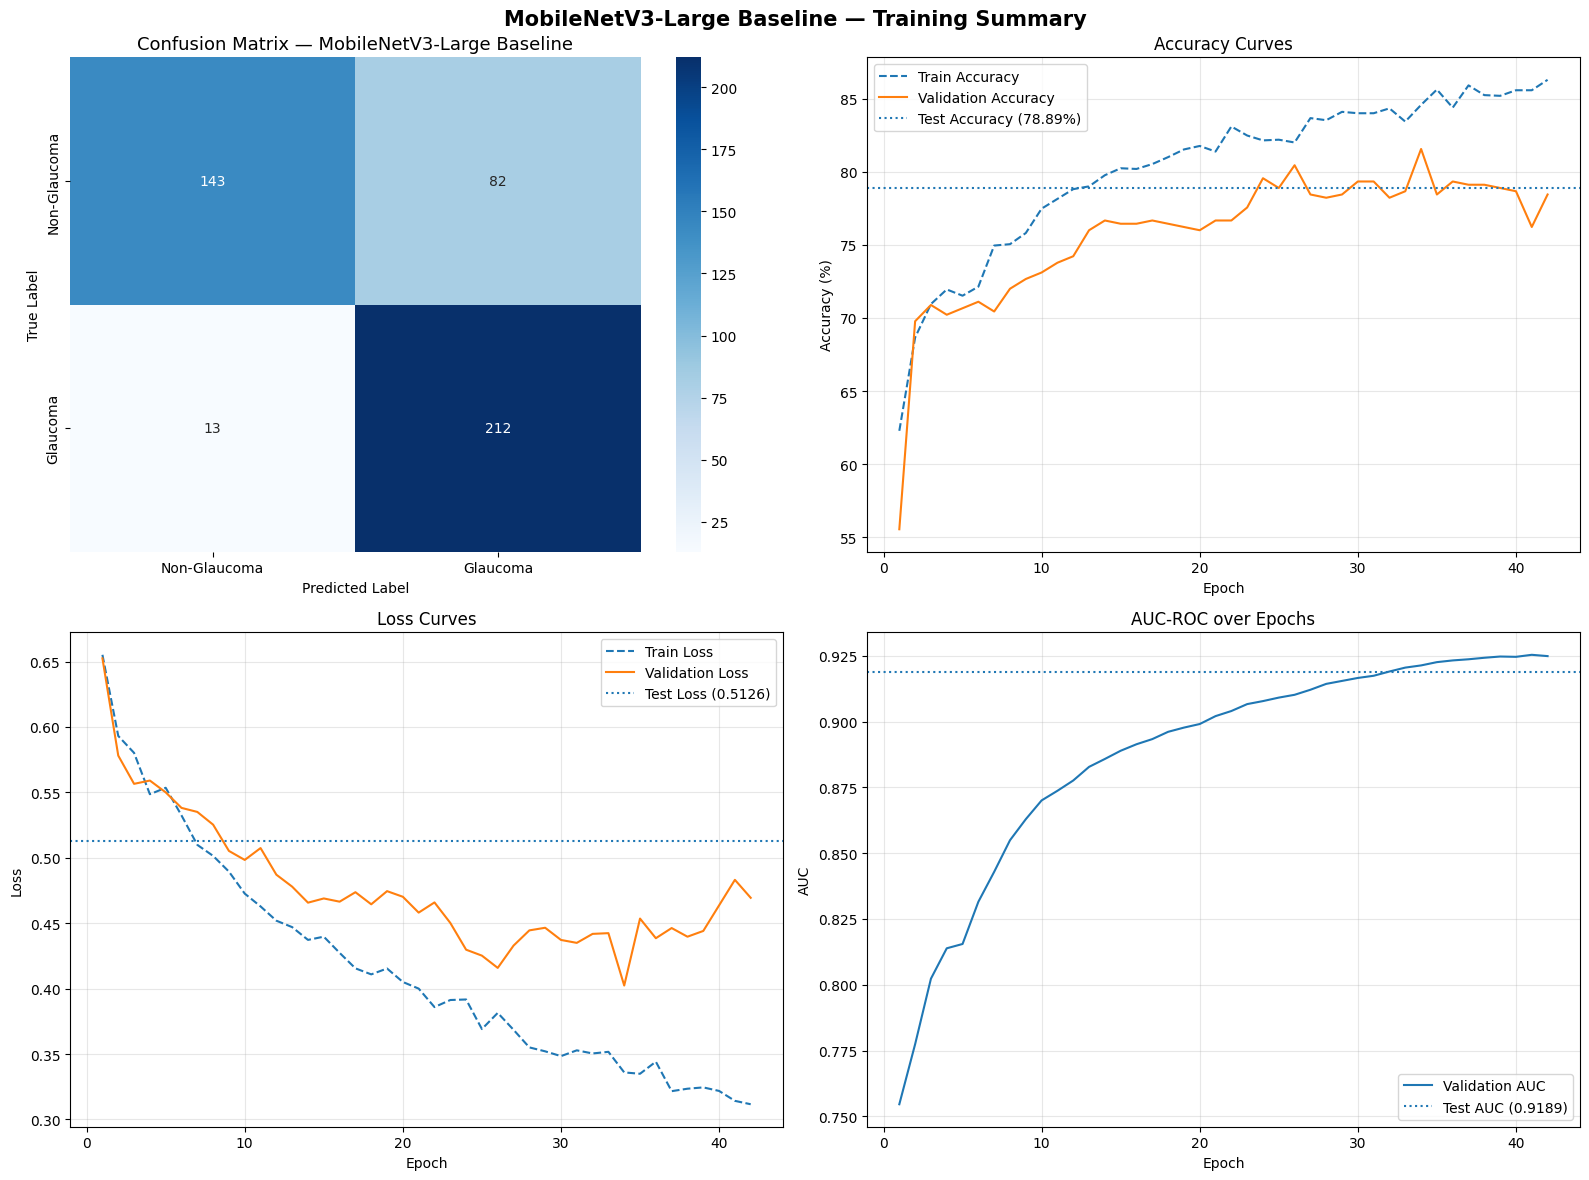


All results saved to: /content/drive/MyDrive/glaucoma-mtl/results/baseline_mobilenetv3_large


In [ ]:
def evaluate_model(model, test_loader, best_ckpt, results_dir, history):
    """
    Full evaluation for MobileNetV3-Large baseline.

    Computes and saves:
      - Accuracy
      - Test Loss
      - Per-class Precision & Recall
      - Macro F1
      - Weighted F1
      - AUC-ROC
      - Sensitivity
      - Specificity
      - Confusion Matrix
      - Accuracy/Loss/AUC training curves
    """

    import os
    import torch.nn as nn
    from sklearn.metrics import (
        accuracy_score,
        roc_auc_score,
        f1_score,
        confusion_matrix,
        classification_report,
        precision_score,
        recall_score,
    )

    # -------------------------------------------------------
    # Load best checkpoint
    # -------------------------------------------------------
    checkpoint = torch.load(best_ckpt, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    criterion = nn.CrossEntropyLoss()

    all_preds = []
    all_probs = []
    all_labels = []

    test_loss_total = 0.0
    test_total = 0

    with torch.no_grad():
        for imgs, labels in tqdm(test_loader, desc="Evaluating"):
            imgs = imgs.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(imgs)

            loss = criterion(outputs, labels)
            test_loss_total += loss.item() * imgs.size(0)
            test_total += imgs.size(0)

            probs = torch.softmax(outputs, dim=1)[:, 1]
            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)
    all_labels = np.array(all_labels)

    # -------------------------------------------------------
    # Metrics
    # -------------------------------------------------------
    test_loss = test_loss_total / test_total

    acc = accuracy_score(all_labels, all_preds)
    auc = roc_auc_score(all_labels, all_probs)

    f1_weighted = f1_score(all_labels, all_preds, average="weighted")
    f1_macro = f1_score(all_labels, all_preds, average="macro")

    cm = confusion_matrix(all_labels, all_preds)

    tn, fp, fn, tp = cm.ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    precision_per_class = precision_score(
        all_labels, all_preds, average=None
    )
    recall_per_class = recall_score(
        all_labels, all_preds, average=None
    )

    normal_precision = precision_per_class[0]
    glaucoma_precision = precision_per_class[1]

    normal_recall = recall_per_class[0]
    glaucoma_recall = recall_per_class[1]

    # Training statistics
    train_acc_final = history["train_acc"][-1] * 100
    val_acc_final = history["val_acc"][-1] * 100
    test_acc = acc * 100

    best_val_acc = max(history["val_acc"]) * 100
    best_val_auc = checkpoint["val_auc"]

    # -------------------------------------------------------
    # Print Results
    # -------------------------------------------------------
    print("\n" + "=" * 65)
    print("BASELINE MobileNetV3-Large — COMPLETE TEST SET RESULTS")
    print("=" * 65)

    print("\n── Accuracy & Loss ───────────────────────────────────────")
    print(f"  Train Accuracy (final epoch): {train_acc_final:.2f}%")
    print(f"  Val   Accuracy (final epoch): {val_acc_final:.2f}%")
    print(f"  Test  Accuracy:               {test_acc:.2f}%")
    print(f"  Best  Val Accuracy:           {best_val_acc:.2f}%")
    print(f"  Test  Loss:                   {test_loss:.4f}")
    print(f"  Best  Val AUC:                {best_val_auc:.4f}")

    print("\n── Per-Class Metrics ─────────────────────────────────────")
    print(f"  Non-Glaucoma Precision: {normal_precision*100:.2f}%")
    print(f"  Non-Glaucoma Recall:    {normal_recall*100:.2f}%")
    print(f"  Glaucoma Precision:     {glaucoma_precision*100:.2f}%")
    print(f"  Glaucoma Recall:        {glaucoma_recall*100:.2f}%")

    print("\n── Overall Metrics ───────────────────────────────────────")
    print(f"  Macro F1:               {f1_macro:.4f}")
    print(f"  Weighted F1:            {f1_weighted:.4f}")
    print(f"  AUC-ROC:                {auc:.4f}")
    print(f"  Sensitivity:            {sensitivity*100:.2f}%")
    print(f"  Specificity:            {specificity*100:.2f}%")

    print("\n── Full Classification Report ────────────────────────────")
    print(
        classification_report(
            all_labels,
            all_preds,
            target_names=["Non-Glaucoma", "Glaucoma"],
        )
    )

    # -------------------------------------------------------
    # Save metrics
    # -------------------------------------------------------
    os.makedirs(results_dir, exist_ok=True)

    with open(f"{results_dir}/baseline_metrics.txt", "w") as f:
        f.write("BASELINE MobileNetV3-Large — COMPLETE TEST SET RESULTS\n")
        f.write("=" * 65 + "\n\n")

        f.write("── Accuracy & Loss ──\n")
        f.write(f"Train Accuracy (final epoch): {train_acc_final:.2f}%\n")
        f.write(f"Val   Accuracy (final epoch): {val_acc_final:.2f}%\n")
        f.write(f"Test  Accuracy:               {test_acc:.2f}%\n")
        f.write(f"Best  Val Accuracy:           {best_val_acc:.2f}%\n")
        f.write(f"Test  Loss:                   {test_loss:.4f}\n")
        f.write(f"Best  Val AUC:                {best_val_auc:.4f}\n\n")

        f.write("── Per-Class Metrics ──\n")
        f.write(f"Non-Glaucoma Precision: {normal_precision*100:.2f}%\n")
        f.write(f"Non-Glaucoma Recall:    {normal_recall*100:.2f}%\n")
        f.write(f"Glaucoma Precision:     {glaucoma_precision*100:.2f}%\n")
        f.write(f"Glaucoma Recall:        {glaucoma_recall*100:.2f}%\n\n")

        f.write("── Overall Metrics ──\n")
        f.write(f"Macro F1:               {f1_macro:.4f}\n")
        f.write(f"Weighted F1:            {f1_weighted:.4f}\n")
        f.write(f"AUC-ROC:                {auc:.4f}\n")
        f.write(f"Sensitivity:            {sensitivity*100:.2f}%\n")
        f.write(f"Specificity:            {specificity*100:.2f}%\n")

    # -------------------------------------------------------
    # Plots
    # -------------------------------------------------------
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # Confusion Matrix
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[0, 0],
        xticklabels=["Non-Glaucoma", "Glaucoma"],
        yticklabels=["Non-Glaucoma", "Glaucoma"],
    )

    axes[0, 0].set_title(
        "Confusion Matrix — MobileNetV3-Large Baseline",
        fontsize=13,
    )
    axes[0, 0].set_xlabel("Predicted Label")
    axes[0, 0].set_ylabel("True Label")

    # Accuracy Curves
    axes[0, 1].plot(
        epochs,
        [v * 100 for v in history["train_acc"]],
        label="Train Accuracy",
        linestyle="--",
    )

    axes[0, 1].plot(
        epochs,
        [v * 100 for v in history["val_acc"]],
        label="Validation Accuracy",
    )

    axes[0, 1].axhline(
        y=test_acc,
        linestyle=":",
        label=f"Test Accuracy ({test_acc:.2f}%)",
    )

    axes[0, 1].set_title("Accuracy Curves")
    axes[0, 1].set_xlabel("Epoch")
    axes[0, 1].set_ylabel("Accuracy (%)")
    axes[0, 1].legend()
    axes[0, 1].grid(alpha=0.3)

    # Loss Curves
    axes[1, 0].plot(
        epochs,
        history["train_loss"],
        label="Train Loss",
        linestyle="--",
    )

    axes[1, 0].plot(
        epochs,
        history["val_loss"],
        label="Validation Loss",
    )

    axes[1, 0].axhline(
        y=test_loss,
        linestyle=":",
        label=f"Test Loss ({test_loss:.4f})",
    )

    axes[1, 0].set_title("Loss Curves")
    axes[1, 0].set_xlabel("Epoch")
    axes[1, 0].set_ylabel("Loss")
    axes[1, 0].legend()
    axes[1, 0].grid(alpha=0.3)

    # AUC Curves
    axes[1, 1].plot(
        epochs,
        history["val_auc"],
        label="Validation AUC",
    )

    axes[1, 1].axhline(
        y=auc,
        linestyle=":",
        label=f"Test AUC ({auc:.4f})",
    )

    axes[1, 1].set_title("AUC-ROC over Epochs")
    axes[1, 1].set_xlabel("Epoch")
    axes[1, 1].set_ylabel("AUC")
    axes[1, 1].legend()
    axes[1, 1].grid(alpha=0.3)

    plt.suptitle(
        "MobileNetV3-Large Baseline — Training Summary",
        fontsize=15,
        fontweight="bold",
    )

    plt.tight_layout()
    plt.savefig(
        f"{results_dir}/baseline_results.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()

    print(f"\nAll results saved to: {results_dir}")

    return acc, auc, f1_weighted, sensitivity, specificity


# ──────────────────────────────────────────────────────────
# Run Evaluation
# ──────────────────────────────────────────────────────────
acc, auc, f1, sens, spec = evaluate_model(
    model,
    test_loader,
    best_ckpt,
    RESULTS_DIR,
    history,
)

## Retrain Model (No Early Stopping)

This section re-initializes the model and retrains it with the same parameters as before, but with early stopping disabled by setting a very high `patience` value. This will allow the model to train for the full number of epochs specified.

In [ ]:
import pandas as pd
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from sklearn.model_selection import train_test_split
from PIL import Image
import torch # For torch.bincount
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import roc_auc_score
from tqdm import tqdm

# Ensure PROJECT_DIR and CKPT_DIR are defined (from WlgqYcw78qQX)
# PROJECT_DIR = '/content/drive/MyDrive/glaucoma-mtl'
# CKPT_DIR = f'{PROJECT_DIR}/checkpoints'
# DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class GlaucomaDataset(Dataset):
    """
    PyTorch Dataset for binary glaucoma classification.
    Reads fundus images from disk, applies transforms.
    """
    def __init__(self, df, transform=None):
        self.df        = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        path  = row['fundus_path']
        label = int(row['label'])

        try:
            img = Image.open(path).convert('RGB')
        except Exception as e:
            img = Image.new('RGB', (224, 224), color=(0, 0, 0))

        if self.transform:
            img = self.transform(img)

        return img, label


def get_transforms():
    """
    Training: standard augmentation (flip, rotate, color jitter, normalize)
    Val/Test: resize + normalize only — no augmentation
    ImageNet mean/std used since DenseNet121 is pretrained on ImageNet
    """
    mean = [0.485, 0.456, 0.406]
    std  = [0.229, 0.224, 0.225]

    train_transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.RandomCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2,
                               saturation=0.1, hue=0.05),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    val_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])

    return train_transform, val_transform


def get_dataloaders(clean_csv_path, batch_size=32, seed=42):
    """
    Loads metadata_clean.csv, splits 70/15/15 (train/val/test),
    stratified by label to maintain class ratio in all splits.
    Returns train/val/test DataLoaders.
    """
    df = pd.read_csv(clean_csv_path)

    # ── Stratified split: 70% train, 15% val, 15% test ────
    train_df, temp_df = train_test_split(
        df, test_size=0.30, stratify=df['label'], random_state=seed
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, stratify=temp_df['label'], random_state=seed
    )

    print(f"Split sizes — Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
    print(f"Train glaucoma ratio: {train_df['label'].mean():.3f}")
    print(f"Val   glaucoma ratio: {val_df['label'].mean():.3f}")
    print(f"Test  glaucoma ratio: {test_df['label'].mean():.3f}")

    train_transform, val_transform = get_transforms()

    train_dataset = GlaucomaDataset(train_df, transform=train_transform)
    val_dataset   = GlaucomaDataset(val_df,   transform=val_transform)
    test_dataset  = GlaucomaDataset(test_df,  transform=val_transform)

    train_loader = DataLoader(train_dataset, batch_size=batch_size,
                              shuffle=True, num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_dataset,   batch_size=batch_size,
                              shuffle=False,  num_workers=2, pin_memory=True)
    test_loader  = DataLoader(test_dataset,  batch_size=batch_size,
                              shuffle=False,  num_workers=2, pin_memory=True)

    return train_loader, val_loader, test_loader, test_df


class EarlyStopping:
    """Stops training if val loss doesn't improve for `patience` epochs."""
    def __init__(self, patience=7, min_delta=0.001):
        self.patience   = patience
        self.min_delta  = min_delta
        self.counter    = 0
        self.best_loss  = None
        self.should_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter   = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True


def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for imgs, labels in tqdm(loader, desc="  Train", leave=False):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)
        preds       = outputs.argmax(dim=1)
        correct    += (preds == labels).sum().item()
        total      += imgs.size(0)

    return total_loss / total, correct / total


def validate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_probs, all_labels = [], []

    with torch.no_grad():
        for imgs, labels in tqdm(loader, desc="  Val  ", leave=False):
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)

            outputs = model(imgs)
            loss    = criterion(outputs, labels)

            total_loss += loss.item() * imgs.size(0)
            preds       = outputs.argmax(dim=1)
            correct    += (preds == labels).sum().item()
            total      += imgs.size(0)

            probs = torch.softmax(outputs, dim=1)[:, 1]
            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / total
    accuracy = correct / total
    auc      = roc_auc_score(all_labels, all_probs)

    return avg_loss, accuracy, auc


def train(model, train_loader, val_loader,
          num_epochs=50, lr=1e-4, weight_decay=1e-4,
          unfreeze_epoch=6, patience=8):
    """
    Full training loop with:
      - Phase 1: frozen backbone (epochs 1 to unfreeze_epoch-1)
      - Phase 2: unfrozen backbone (epochs unfreeze_epoch onward)
      - ReduceLROnPlateau scheduler
      - Early stopping on val loss
      - Checkpoint saves best model by val AUC
    """
    criterion    = nn.CrossEntropyLoss()
    optimizer    = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=4
)
    early_stop   = EarlyStopping(patience=patience)

    best_auc     = 0.0
    # Use a unique checkpoint path for this training run
    best_ckpt_path = f'{CKPT_DIR}/baseline_mobilenetv3_large_no_early_stop_temp_best.pth'
    history      = {'train_loss': [], 'val_loss': [],
                    'train_acc':  [], 'val_acc': [], 'val_auc': []}

    for epoch in range(1, num_epochs + 1):

        # ── Unfreeze backbone at unfreeze_epoch ───────────
        if epoch == unfreeze_epoch:
            print(f"\nEpoch {epoch}: Unfreezing backbone for end-to-end fine-tuning...")
            for param in model.features.parameters():
                param.requires_grad = True
            # Rebuild optimizer to include newly unfrozen params
            optimizer = optim.Adam(
                model.parameters(), lr=lr * 0.1, weight_decay=weight_decay
            )
            scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=4
)

        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss,   val_acc, val_auc = validate(model, val_loader, criterion)

        scheduler.step(val_auc)
        early_stop(val_loss)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['val_auc'].append(val_auc)

        print(f"Epoch [{epoch:02d}/{num_epochs}] "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | "
              f"Val AUC: {val_auc:.4f}")

        # ── Save best checkpoint ───────────────────────────
        if val_auc > best_auc:
            best_auc = val_auc
            torch.save({
                'epoch':      epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_auc':    val_auc,
                'val_acc':    val_acc,
            }, best_ckpt_path)
            print(f"  ✓ Best model saved (AUC: {best_auc:.4f})")

        if early_stop.should_stop:
            print(f"\nEarly stopping triggered at epoch {epoch}.")
            break

    print(f"\nTraining complete. Best Val AUC: {best_auc:.4f}")
    print(f"Checkpoint saved to: {best_ckpt_path}")

    return history, best_ckpt_path


# --- End of copied function definitions ---


print("\n--- Retraining without Early Stopping ---")

# Ensure FINAL_CSV is defined
FINAL_CSV = f'{PROJECT_DIR}/metadata_final.csv'

# Build DataLoaders - these need to be recreated or obtained if not in scope
print("Building DataLoaders...")
train_loader, val_loader, test_loader, test_df = get_dataloaders(FINAL_CSV)
print("DataLoaders OK.")

# Re-initialize the model for a fresh training run
model_no_early_stop = build_model(freeze_backbone=True)
print(f"\nModel on device: {next(model_no_early_stop.parameters()).device}")

# Run Training without early stopping (set patience to a very high number)
history_no_early_stop, best_ckpt_no_early_stop_path = train(
    model_no_early_stop, train_loader, val_loader,
    num_epochs=50,
    lr=1e-4,
    weight_decay=1e-4,
    unfreeze_epoch=6,
    patience=100 # Effectively disables early stopping for 50 epochs
)

print(f"Final model without early stopping saved to: {best_ckpt_no_early_stop_path}")


--- Retraining without Early Stopping ---
Building DataLoaders...
Split sizes — Train: 2100 | Val: 450 | Test: 450
Train glaucoma ratio: 0.500
Val   glaucoma ratio: 0.500
Test  glaucoma ratio: 0.500
DataLoaders OK.
Backbone frozen — training head only.
Total params:    3,465,010
Trainable params:493,058

Model on device: cuda:0


Epoch [01/50] Train Loss: 0.6561 | Train Acc: 0.6152 | Val Loss: 0.6299 | Val Acc: 0.6533 | Val AUC: 0.7467
  ✓ Best model saved (AUC: 0.7467)


Epoch [02/50] Train Loss: 0.5959 | Train Acc: 0.6910 | Val Loss: 0.5790 | Val Acc: 0.6867 | Val AUC: 0.7911
  ✓ Best model saved (AUC: 0.7911)


Epoch [03/50] Train Loss: 0.5776 | Train Acc: 0.7033 | Val Loss: 0.5466 | Val Acc: 0.7000 | Val AUC: 0.7995
  ✓ Best model saved (AUC: 0.7995)


Epoch [04/50] Train Loss: 0.5625 | Train Acc: 0.7133 | Val Loss: 0.5416 | Val Acc: 0.7222 | Val AUC: 0.8121
  ✓ Best model saved (AUC: 0.8121)


...

Epoch [46/50] Train Loss: 0.3198 | Train Acc: 0.8524 | Val Loss: 0.4397 | Val Acc: 0.8000 | Val AUC: 0.9240


Epoch [47/50] Train Loss: 0.3187 | Train Acc: 0.8533 | Val Loss: 0.4188 | Val Acc: 0.8156 | Val AUC: 0.9245
  ✓ Best model saved (AUC: 0.9245)


Epoch [48/50] Train Loss: 0.3152 | Train Acc: 0.8529 | Val Loss: 0.4264 | Val Acc: 0.8089 | Val AUC: 0.9262
  ✓ Best model saved (AUC: 0.9262)


Epoch [49/50] Train Loss: 0.3004 | Train Acc: 0.8652 | Val Loss: 0.4243 | Val Acc: 0.8067 | Val AUC: 0.9272
  ✓ Best model saved (AUC: 0.9272)


Epoch [50/50] Train Loss: 0.2969 | Train Acc: 0.8724 | Val Loss: 0.4323 | Val Acc: 0.8067 | Val AUC: 0.9275
  ✓ Best model saved (AUC: 0.9275)

Training complete. Best Val AUC: 0.9275
Checkpoint saved to: /content/drive/MyDrive/glaucoma-mtl/checkpoints/baseline_mobilenetv3_large_no_early_stop_temp_best.pth
Final model without early stopping saved to: /content/drive/MyDrive/glaucoma-mtl/checkpoints/baseline_mobilenetv3_large_no_early_stop_temp_best.pth


Evaluating: 100%|██████████| 15/15 [01:34<00:00,  6.28s/it]



BASELINE MobileNetV3-Large — COMPLETE TEST SET RESULTS

── Accuracy & Loss ───────────────────────────────────────
  Train Accuracy (final epoch): 87.24%
  Val   Accuracy (final epoch): 80.67%
  Test  Accuracy:               82.89%
  Best  Val Accuracy:           81.56%
  Test  Loss:                   0.4531
  Best  Val AUC:                0.9275

── Per-Class Metrics ─────────────────────────────────────
  Non-Glaucoma Precision: 92.53%
  Non-Glaucoma Recall:    71.56%
  Glaucoma Precision:     76.81%
  Glaucoma Recall:        94.22%

── Overall Metrics ───────────────────────────────────────
  Macro F1:               0.8267
  Weighted F1:            0.8267
  AUC-ROC:                0.9255
  Sensitivity:            94.22%
  Specificity:            71.56%

── Full Classification Report ────────────────────────────
              precision    recall  f1-score   support

Non-Glaucoma       0.93      0.72      0.81       225
    Glaucoma       0.77      0.94      0.85       225

    accur

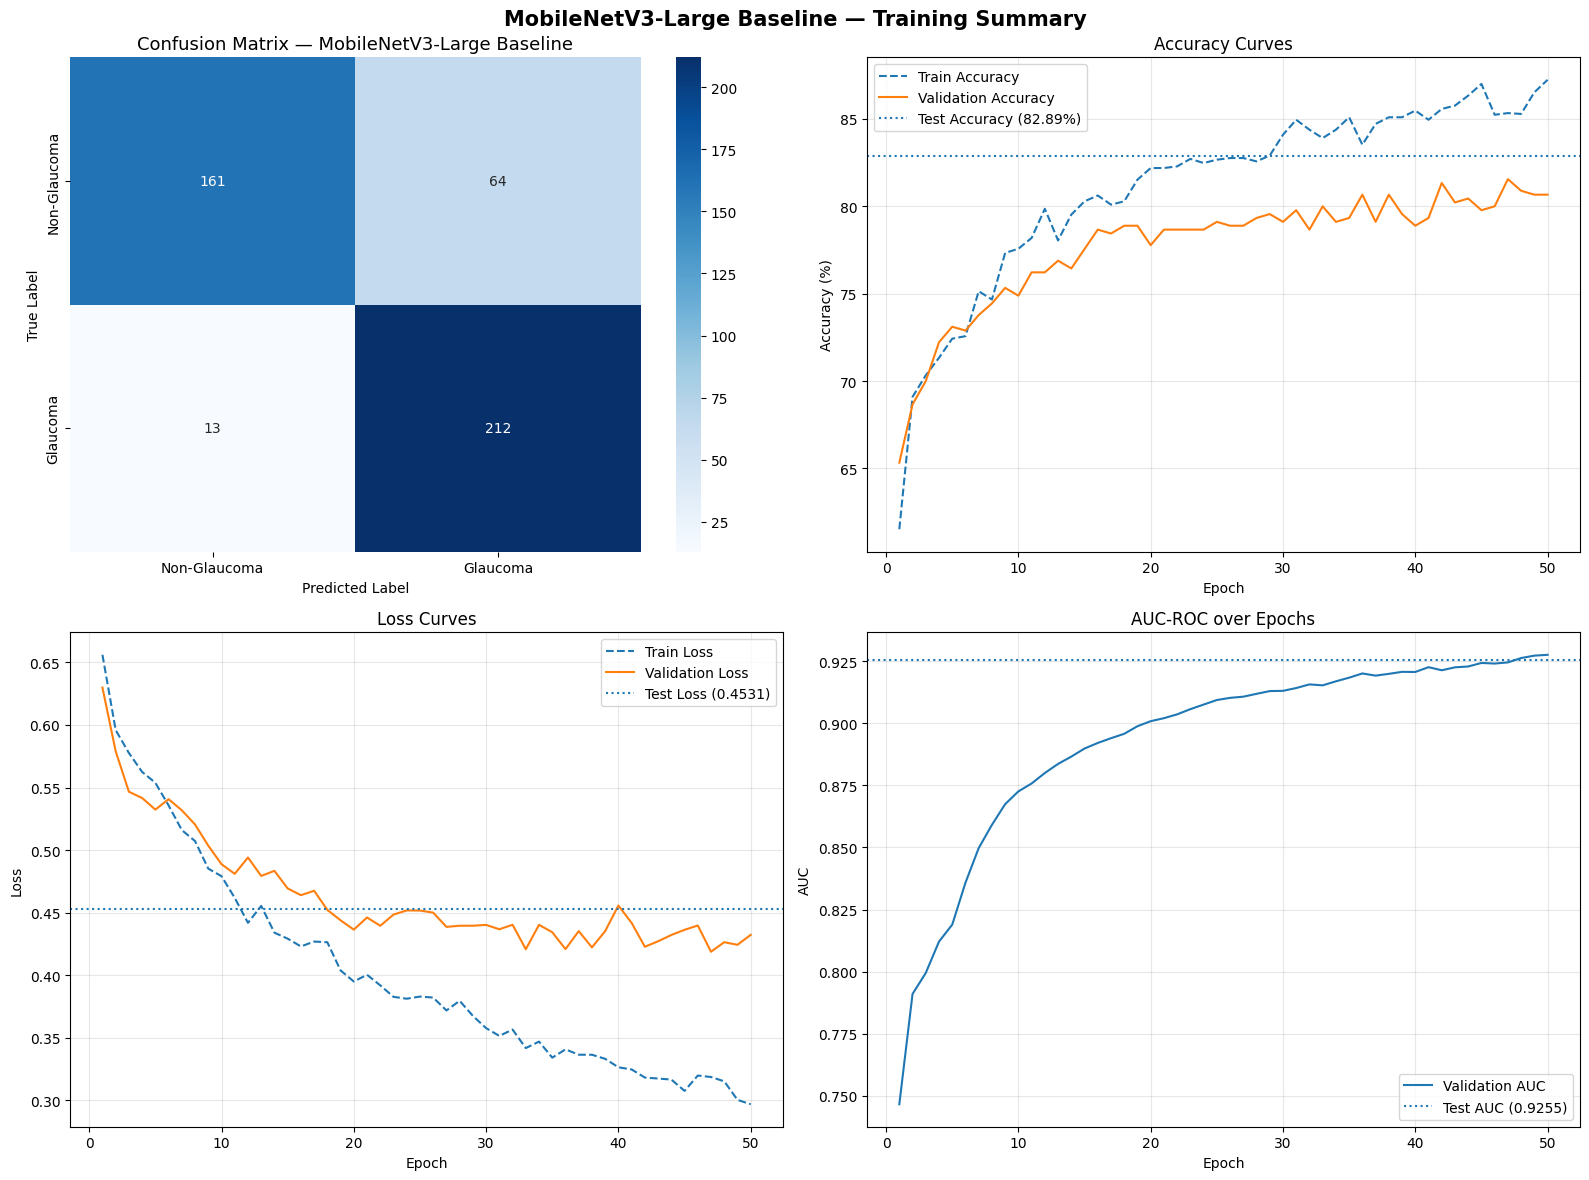


All results saved to: /content/drive/MyDrive/glaucoma-mtl/results/baseline_mobilenetv3_large/no_early_stopping


In [ ]:
import os
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import torch


def evaluate_model(model, test_loader, best_ckpt, results_dir, history):
    """
    Full evaluation for MobileNetV3-Large baseline.

    Computes and saves:
      - Accuracy
      - Test Loss
      - Per-class Precision & Recall
      - Macro F1
      - Weighted F1
      - AUC-ROC
      - Sensitivity
      - Specificity
      - Confusion Matrix
      - Accuracy/Loss/AUC training curves
    """

    # -------------------------------------------------------
    # Load best checkpoint
    # -------------------------------------------------------
    # Ensure DEVICE is defined, e.g., from an earlier setup cell
    global DEVICE # Assuming DEVICE is a global variable

    checkpoint = torch.load(best_ckpt, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    criterion = nn.CrossEntropyLoss()

    all_preds = []
    all_probs = []
    all_labels = []

    test_loss_total = 0.0
    test_total = 0

    with torch.no_grad():
        for imgs, labels in tqdm(test_loader, desc="Evaluating"):
            imgs = imgs.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(imgs)

            loss = criterion(outputs, labels)
            test_loss_total += loss.item() * imgs.size(0)
            test_total += imgs.size(0)

            probs = torch.softmax(outputs, dim=1)[:, 1]
            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)
    all_labels = np.array(all_labels)

    # -------------------------------------------------------
    # Metrics
    # -------------------------------------------------------
    test_loss = test_loss_total / test_total

    acc = accuracy_score(all_labels, all_preds)
    auc = roc_auc_score(all_labels, all_probs)

    f1_weighted = f1_score(all_labels, all_preds, average="weighted")
    f1_macro = f1_score(all_labels, all_preds, average="macro")

    cm = confusion_matrix(all_labels, all_preds)

    tn, fp, fn, tp = cm.ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    precision_per_class = precision_score(
        all_labels, all_preds, average=None
    )
    recall_per_class = recall_score(
        all_labels, all_preds, average=None
    )

    normal_precision = precision_per_class[0]
    glaucoma_precision = precision_per_class[1]

    normal_recall = recall_per_class[0]
    glaucoma_recall = recall_per_class[1]

    # Training statistics
    train_acc_final = history["train_acc"][-1] * 100
    val_acc_final = history["val_acc"][-1] * 100
    test_acc = acc * 100

    best_val_acc = max(history["val_acc"]) * 100
    best_val_auc = checkpoint["val_auc"]

    # -------------------------------------------------------
    # Print Results
    # -------------------------------------------------------
    print("\n" + "=" * 65)
    print("BASELINE MobileNetV3-Large — COMPLETE TEST SET RESULTS")
    print("=" * 65)

    print("\n── Accuracy & Loss ───────────────────────────────────────")
    print(f"  Train Accuracy (final epoch): {train_acc_final:.2f}%")
    print(f"  Val   Accuracy (final epoch): {val_acc_final:.2f}%")
    print(f"  Test  Accuracy:               {test_acc:.2f}%")
    print(f"  Best  Val Accuracy:           {best_val_acc:.2f}%")
    print(f"  Test  Loss:                   {test_loss:.4f}")
    print(f"  Best  Val AUC:                {best_val_auc:.4f}")

    print("\n── Per-Class Metrics ─────────────────────────────────────")
    print(f"  Non-Glaucoma Precision: {normal_precision*100:.2f}%")
    print(f"  Non-Glaucoma Recall:    {normal_recall*100:.2f}%")
    print(f"  Glaucoma Precision:     {glaucoma_precision*100:.2f}%")
    print(f"  Glaucoma Recall:        {glaucoma_recall*100:.2f}%")

    print("\n── Overall Metrics ───────────────────────────────────────")
    print(f"  Macro F1:               {f1_macro:.4f}")
    print(f"  Weighted F1:            {f1_weighted:.4f}")
    print(f"  AUC-ROC:                {auc:.4f}")
    print(f"  Sensitivity:            {sensitivity*100:.2f}%")
    print(f"  Specificity:            {specificity*100:.2f}%")

    print("\n── Full Classification Report ────────────────────────────")
    print(
        classification_report(
            all_labels,
            all_preds,
            target_names=["Non-Glaucoma", "Glaucoma"],
        )
    )

    # -------------------------------------------------------
    # Save metrics
    # -------------------------------------------------------
    os.makedirs(results_dir, exist_ok=True)

    with open(f"{results_dir}/baseline_metrics.txt", "w") as f:
        f.write("BASELINE MobileNetV3-Large — COMPLETE TEST SET RESULTS\n")
        f.write("=" * 65 + "\n\n")

        f.write("── Accuracy & Loss ──\n")
        f.write(f"Train Accuracy (final epoch): {train_acc_final:.2f}%\n")
        f.write(f"Val   Accuracy (final epoch): {val_acc_final:.2f}%\n")
        f.write(f"Test  Accuracy:               {test_acc:.2f}%\n")
        f.write(f"Best  Val Accuracy:           {best_val_acc:.2f}%\n")
        f.write(f"Test  Loss:                   {test_loss:.4f}\n")
        f.write(f"Best  Val AUC:                {best_val_auc:.4f}\n\n")

        f.write("── Per-Class Metrics ──\n")
        f.write(f"Non-Glaucoma Precision: {normal_precision*100:.2f}%\n")
        f.write(f"Non-Glaucoma Recall:    {normal_recall*100:.2f}%\n")
        f.write(f"Glaucoma Precision:     {glaucoma_precision*100:.2f}%\n")
        f.write(f"Glaucoma Recall:        {glaucoma_recall*100:.2f}%\n\n")

        f.write("── Overall Metrics ──\n")
        f.write(f"Macro F1:               {f1_macro:.4f}\n")
        f.write(f"Weighted F1:            {f1_weighted:.4f}\n")
        f.write(f"AUC-ROC:                {auc:.4f}\n")
        f.write(f"Sensitivity:            {sensitivity*100:.2f}%\n")
        f.write(f"Specificity:            {specificity*100:.2f}%\n")

    # -------------------------------------------------------
    # Plots
    # -------------------------------------------------------
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # Confusion Matrix
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[0, 0],
        xticklabels=["Non-Glaucoma", "Glaucoma"],
        yticklabels=["Non-Glaucoma", "Glaucoma"],
    )

    axes[0, 0].set_title(
        "Confusion Matrix — MobileNetV3-Large Baseline",
        fontsize=13,
    )
    axes[0, 0].set_xlabel("Predicted Label")
    axes[0, 0].set_ylabel("True Label")

    # Accuracy Curves
    axes[0, 1].plot(
        epochs,
        [v * 100 for v in history["train_acc"]],
        label="Train Accuracy",
        linestyle="--",
    )

    axes[0, 1].plot(
        epochs,
        [v * 100 for v in history["val_acc"]],
        label="Validation Accuracy",
    )

    axes[0, 1].axhline(
        y=test_acc,
        linestyle=":",
        label=f"Test Accuracy ({test_acc:.2f}%)",
    )

    axes[0, 1].set_title("Accuracy Curves")
    axes[0, 1].set_xlabel("Epoch")
    axes[0, 1].set_ylabel("Accuracy (%)")
    axes[0, 1].legend()
    axes[0, 1].grid(alpha=0.3)

    # Loss Curves
    axes[1, 0].plot(
        epochs,
        history["train_loss"],
        label="Train Loss",
        linestyle="--",
    )

    axes[1, 0].plot(
        epochs,
        history["val_loss"],
        label="Validation Loss",
    )

    axes[1, 0].axhline(
        y=test_loss,
        linestyle=":",
        label=f"Test Loss ({test_loss:.4f})",
    )

    axes[1, 0].set_title("Loss Curves")
    axes[1, 0].set_xlabel("Epoch")
    axes[1, 0].set_ylabel("Loss")
    axes[1, 0].legend()
    axes[1, 0].grid(alpha=0.3)

    # AUC Curves
    axes[1, 1].plot(
        epochs,
        history["val_auc"],
        label="Validation AUC",
    )

    axes[1, 1].axhline(
        y=auc,
        linestyle=":",
        label=f"Test AUC ({auc:.4f})",
    )

    axes[1, 1].set_title("AUC-ROC over Epochs")
    axes[1, 1].set_xlabel("Epoch")
    axes[1, 1].set_ylabel("AUC")
    axes[1, 1].legend()
    axes[1, 1].grid(alpha=0.3)

    plt.suptitle(
        "MobileNetV3-Large Baseline — Training Summary",
        fontsize=15,
        fontweight="bold",
    )

    plt.tight_layout()
    plt.savefig(
        f"{results_dir}/baseline_results.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()

    print(f"\nAll results saved to: {results_dir}")

    return acc, auc, f1_weighted, sensitivity, specificity


# ──────────────────────────────────────────────────────────
# Run Evaluation for model without early stopping
# ──────────────────────────────────────────────────────────
acc_no_es, auc_no_es, f1_no_es, sens_no_es, spec_no_es = evaluate_model(
    model_no_early_stop,
    test_loader,
    best_ckpt_no_early_stop_path,
    f'{RESULTS_DIR}/no_early_stopping',
    history_no_early_stop,
)